# Model Testing — Most_Magnificent_Model

This notebook checks the Most_Magnificent_Model model. It **runs `Most_Magnificent_Model.ipynb` first** (so it always tests exactly the current code and settings), then:

| Section | Question it answers |
|---|---|
| A. Data checks | Did every source download? Is anything stale? Did Kalshi's automatic search find every race (and did any request fail)? Is the calibration loaded? Are the candidate-history rows the current nominees? How many LV/RV pairs measured the RV shift? |
| B. Model sanity checks | Are the numbers internally consistent (probabilities 0–100%, shares add to 1, seat counts possible, the two simulations agree)? |
| C. Coverage by race | Which contested races rest on thin polling? |
| D. Disagreements with Kalshi | Where do the model and the market differ by a lot, and why? |
| E. Robustness | Which settings move the answer most (Model 1's sweep + the new settings)? Which races are most assumption-sensitive? Do the toggles and random seeds change much? |
| F. Trajectory | How has the forecast moved week by week (backtests)? |
| G. Summary | One table of every check, saved to `Output/testing/` |

**Reading the checks:** **PASS** (fine), **WARN** (worth a look, doesn't stop the model), **FAIL** (something is broken; don't publish this run). Takes a few minutes: the sweep and trajectory re-run the model about 100 times with fewer simulations.


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


run_all.py overrides: AS_OF_DATE = None, N_SIMS = 100,000
Calibration applied: 2026-10-29 22:45 (FiveThirtyEight raw_polls.csv (live (GitHub)); Final Model/calibration.ipynb)


,CONFIG value,calibrated value
setting,,
PRIOR_SD,7.50,9.320
SYSTEMATIC_POLL_ERROR_SD,4.50,3.870
DAILY_DRIFT_SD,0.25,0.762
INCUMBENCY_ADVANTAGE,2.00,3.780
CANDIDATE_EFFECT_WEIGHT,0.30,0.298
NATIONAL_ERROR_SD,2.50,2.520
RECENCY_HALF_LIFE_DAYS,21.00,7.000
HOUSE_EFFECT_K,5.00,5.000
REGIONAL_ERROR_SD,1.50,1.510


35 races | D needs 51 seats (17 wins) | repo root: C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast


...

,margin,Model 1-style (no Kalshi),P(D/Ind win),Kalshi P,model - Kalshi,rating
State,,,,,,
Massachusetts,D+34.3,D+34.3,100%,98%,+2%,Safe D
Rhode Island,D+25.5,D+25.5,100%,99%,+1%,Safe D
Virginia,D+18.9,D+18.9,100%,98%,+1%,Safe D
Illinois,D+17.6,D+17.6,100%,98%,+2%,Safe D
Delaware,D+29.1,D+29.1,100%,98%,+1%,Safe D
Oregon,D+29.1,D+29.1,100%,99%,+1%,Safe D
New Mexico,D+18.9,D+18.9,100%,99%,+1%,Safe D
Colorado,D+25.1,D+25.1,99%,98%,+1%,Safe D
North Carolina,D+12.3,D+12.3,99%,96%,+3%,Safe D


,State,candidate,race,their margin,generic baseline,over-performance (D-R),used,why not,pts added to prior
0,Maine,Susan Collins,2020 Senate,-8.6,+7.7,-16.3,True,,-4.9
1,Alaska,Dan Sullivan,2020 Senate,-12.7,-11.4,-1.3,True,,-0.4
2,Alaska,Mary Peltola,2024 US House at-large (statewide),-2.6,-14.2,+11.7,True,,+3.5
3,Nebraska,Dan Osborn,2024 Senate,-6.7,-21.6,+14.9,True,,+4.4
4,Nebraska,Pete Ricketts,2024 Senate (special),-25.2,-21.6,-3.6,True,,-1.1
5,Ohio,Sherrod Brown,2024 Senate,-3.6,-12.3,+8.7,True,,+2.6
6,North Carolina,Roy Cooper,2020 Governor,+4.5,-2.7,+7.2,True,,+2.2
7,Georgia,Jon Ossoff,2020 Senate (November general),-1.8,-1.1,-0.7,True,,-0.2
8,Michigan,Mike Rogers,2024 Senate,+0.3,-2.5,+2.9,True,,+0.9
9,Kansas,Roger Marshall,2020 Senate,-11.4,-16.0,+4.6,True,,+1.4


,polls,graded,avg_residual,scorecard_lean,lean_used
Pollster,,,,,
Quantus Insights,11,True,-6.2,-1.0,-4.5
East Carolina University,3,True,-4.9,-0.6,-2.2
co/efficient,3,False,-4.7,-0.1,-1.8
InsiderAdvantage,15,True,-1.8,-0.6,-1.5
National Public Affairs,3,False,-1.8,-0.1,-0.7
University of New Hampshire,4,False,-1.5,-0.1,-0.7
The New York Times/Siena University,3,True,-2.2,+0.4,-0.6
Beacon Research/Shaw & Co. Research,6,True,-1.3,+0.6,-0.4
Emerson College,7,True,-0.4,-0.3,-0.3


,deciding-seat share,P(D/Ind win),margin
State,,,
Texas,13.0%,69%,D+2.3
Alaska,11.8%,59%,D+1.1
Ohio,11.8%,76%,D+3.3
Maine,11.5%,75%,D+3.1
Kansas,9.2%,48%,R+0.3
Iowa,9.2%,45%,R+0.5
Michigan,7.7%,88%,D+5.4
Minnesota,6.2%,90%,D+6.3
South Carolina,5.1%,28%,R+2.6


P(D wins Kansas) = 0.48 | if D wins Iowa: 0.62 | if D loses Iowa: 0.36
P(D wins New Hampshire) = 0.95 | if D wins Maine: 0.97 | if D loses Maine: 0.89
P(D wins Ohio) = 0.76 | if D wins Texas: 0.82 | if D loses Texas: 0.64
P(D wins Minnesota) = 0.90 | if D wins Michigan: 0.92 | if D loses Michigan: 0.81


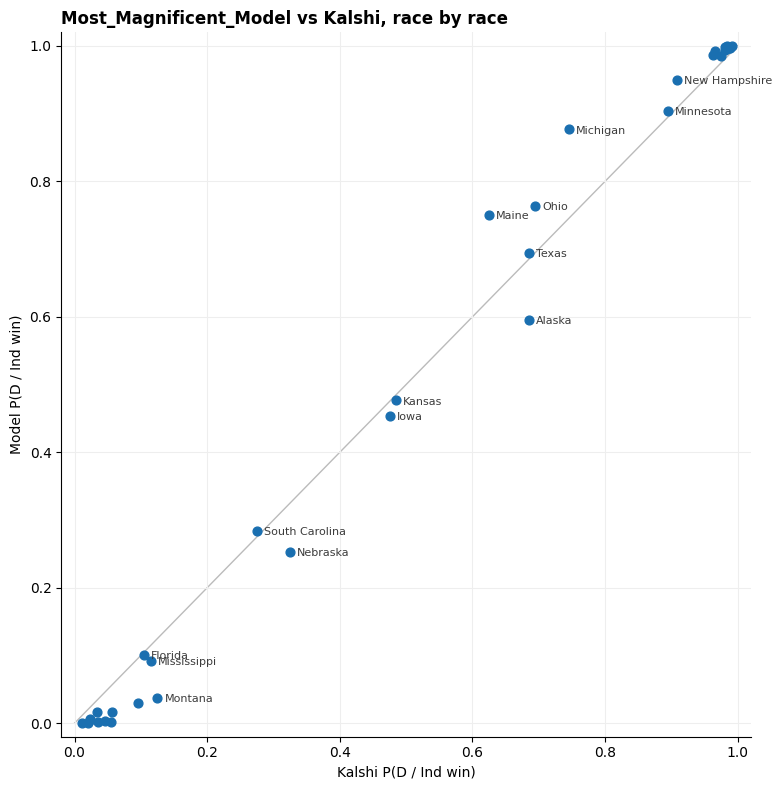

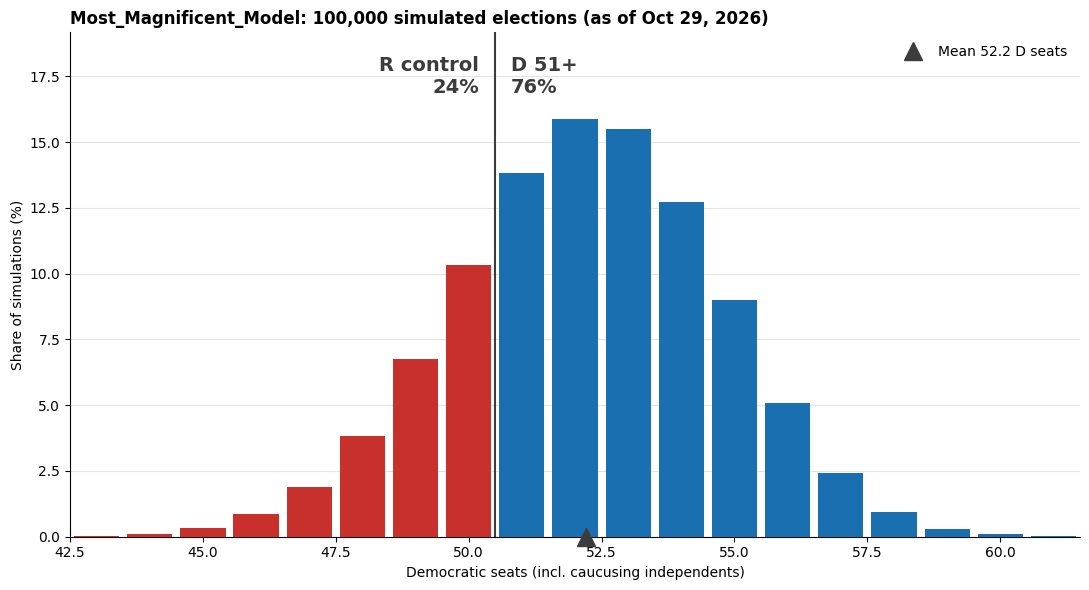

Saved race_probabilities.csv, state_win_probabilities.csv, polls_used.csv, national_signals.csv, seat_distribution.csv/.png, model_vs_kalshi.png, config_snapshot.json, headline.json to C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\Most_Magnificent_Model\Output
Standard export -> C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\Most_Magnificent_Model\Output\standard


In [1]:
%run ./Most_Magnificent_Model.ipynb

In [2]:
TEST_DIR = CONFIG["OUT_DIR"] / "testing"
TEST_DIR.mkdir(parents=True, exist_ok=True)
CHECKS = []


def check(section, name, status, detail):
    """Record one check. status: PASS / WARN / FAIL."""
    CHECKS.append({"section": section, "check": name, "status": status, "detail": detail})


COLORS = {"PASS": "background-color:#DFF0D8", "WARN": "background-color:#FCF8E3", "FAIL": "background-color:#F2DEDE"}


def show(section):
    t = pd.DataFrame([c for c in CHECKS if c["section"] == section])
    if not len(t):
        return
    try:
        display(t.drop(columns="section").style.map(lambda v: COLORS.get(v, ""), subset=["status"]))
    except (AttributeError, ImportError):
        display(t.drop(columns="section"))


def show_df(df, fmt=None):
    try:
        display(df.style.format(fmt or {}))
    except (AttributeError, ImportError):
        display(df.round(3))


SIM_N = 3000  # simulations per re-run in sections E and F (fewer than the main run, for speed)
r, polls, env, today = RES["races"], RES["polls"], RES["env"], RES["today"]

## A. Data checks
- **Sources:** each download should say *live*. *cache* means the website was unreachable and the last saved copy was used.
- **Freshness:** the newest state poll should be under 7 days old and the newest national poll under 21 days.
- **Kalshi search vs the fallback table:** any race where the search found a *different* market, or fell back to the table, is listed.
- **Nominees:** taken from Kalshi's candidate names; disagreements with the fallback table are listed.
- **Ungraded pollsters:** what share of the poll weight rests on firms VoteHub hasn't graded (these get random grades).

In [3]:
for name, stat in SOURCE_STATUS.items():
    check("A", f"source: {name}", "PASS" if stat == "live" else "WARN", stat)

newest = DATA["senate"]["end_date"].max()
age = (today - newest).days
check("A", "newest state poll", "PASS" if age <= 7 else "WARN", f"{newest:%Y-%m-%d} ({age} days old)")
for nm, df in [("generic ballot", DATA["generic"]), ("approval", DATA["approval"])]:
    d = df.loc[df["Date"] <= today, "Date"].max()
    a = (today - d).days
    check("A", f"newest {nm} poll (VoteHub)", "PASS" if a <= 21 else "WARN",
          f"{d:%Y-%m-%d} ({a} days old){' - Kalshi averages fill the gap' if a > 21 else ''}")
fk = DATA["kalshi_races"]["fetched"].iloc[0] if "fetched" in DATA["kalshi_races"] else "?"
check("A", "Kalshi race prices date", "PASS" if str(fk) == pd.Timestamp.today().strftime("%Y-%m-%d") else "WARN", f"fetched {fk}")

kc = KALSHI_CHECK
missing = kc.index[kc["found_event"].isna()].tolist()
check("A", "Kalshi races found", "PASS" if not missing else "FAIL", f"{kc['found_event'].notna().sum()}/35" + (f"; missing {missing}" if missing else ""))
fb = kc.index[kc["found_by"] == "fallback table"].tolist()
check("A", "Kalshi races found by title search", "PASS" if not fb else "WARN", "all" if not fb else f"used the fallback table for {fb}")
diff = kc[~kc["matches_fallback_table"] & kc["found_event"].notna()]
check("A", "Kalshi search agrees with fallback table", "PASS" if diff.empty else "WARN",
      "all agree" if diff.empty else "; ".join(f"{st}: found {a}, table {b}" for st, (a, b) in diff[["found_event", "fallback_table"]].iterrows()))
nd = NOMINEE_CHECK[~NOMINEE_CHECK["matches_fallback_table"]]
check("A", "nominees agree with fallback table", "PASS" if nd.empty else "WARN",
      "all 35 agree" if nd.empty else "; ".join(f"{st}: {row['republican']} vs {row['opposition']}" for st, row in nd.iterrows()))
part = NOMINEE_CHECK.index[NOMINEE_CHECK["source"] != "Kalshi"].tolist()
check("A", "nominees from Kalshi names", "PASS" if len(part) <= 1 else "WARN",
      f"{35 - len(part)}/35 from Kalshi; fallback table used for {part}")
check("A", "polls dropped for missing nominees", "PASS" if N_UNMATCHED <= 0.2 * max(len(DATA["senate"]), 1) else "WARN",
      f"{N_UNMATCHED} of {len(DATA['senate'])} VoteHub rows (old hypothetical match-ups)")
if len(polls):
    sh = polls.loc[polls["Unrated"], "weight"].sum() / polls["weight"].sum()
    check("A", "weight from ungraded pollsters", "PASS" if sh < 0.5 else "WARN",
          f"{polls['Unrated'].sum()} of {len(polls)} polls, {sh:.0%} of poll weight ({CONFIG['UNRATED_POLLSTERS']} grades)")
for sig, row in env["table"].iterrows():
    check("A", f"national: {sig}", "PASS" if row["effective n (fresh)"] >= 3 or row["Kalshi counts as"] > 0 else "WARN",
          f"{row['n polls']:.0f} VoteHub polls (= {row['effective n (fresh)']:.1f} fresh polls) + Kalshi counted as "
          f"{row['Kalshi counts as']:.0f} -> {row['combined']:+.1f}")
# ---- MMM checks ----
check("A", "Kalshi requests", "PASS" if not KALSHI_LOG else "WARN",
      "no failed requests" if not KALSHI_LOG else f"{len(KALSHI_LOG)} failed after retries: " + "; ".join(x["request"] for x in KALSHI_LOG[:6]))
if CALIBRATION:
    age_c = (pd.Timestamp.today() - pd.Timestamp(CALIBRATION["created"])).days
    check("A", "calibration", "PASS" if CALIBRATION.get("model") == "most_magnificent_model" else "WARN",
          f"calibration.json from {CALIBRATION['created']} ({age_c} days old), {len(CALIBRATION['overrides'])} settings, model {CALIBRATION.get('model')}")
else:
    check("A", "calibration", "WARN", "no calibration.json applied: CONFIG values as written (run Final Model/calibration.ipynb)")
if len(CANDIDATE_TABLE):
    bad = CANDIDATE_TABLE[(~CANDIDATE_TABLE["used"]) & (CANDIDATE_TABLE["why not"] == "not the 2026 nominee")]
    check("A", "candidate history matches the nominees", "PASS" if bad.empty else "WARN",
          f"{int(CANDIDATE_TABLE['used'].sum())} rows used" + ("" if bad.empty else f"; not the nominee: {', '.join(bad['candidate'])}"))
else:
    check("A", "candidate history", "WARN" if CONFIG["CANDIDATE_EFFECTS"] else "PASS", "no rows used")
s_ = RES["summary"]
check("A", "RV shift", "PASS" if CONFIG["RV_MARGIN_SHIFT"] != "estimate" or s_["rv_pairs"] >= 5 else "WARN",
      f"{s_['rv_shift']:+.2f} pts" + (f" from {s_['rv_pairs']} LV/RV survey pairs" if CONFIG["RV_MARGIN_SHIFT"] == "estimate" else " (fixed)"))
check("A", "undecided share U used for Kalshi approval", "PASS" if 0 <= env["U"] <= 10 else "WARN", f"U = {env['U']:.1f} pts")
if CONFIG["SCORECARD_HOUSE_EFFECTS"] and CONFIG["ESTIMATE_HOUSE_EFFECTS"]:
    check("A", "house effects corrected twice", "WARN", "SCORECARD_HOUSE_EFFECTS and ESTIMATE_HOUSE_EFFECTS are both on")
show("A")

,check,status,detail
0,source: votehub_senate_cache.csv,PASS,live
1,source: votehub_generic_ballot_cache.csv,PASS,live
2,source: votehub_approval_cache.csv,PASS,live
3,source: kalshi_races_cache.csv,PASS,live
4,source: kalshi_national_cache.csv,PASS,live
5,newest state poll,PASS,2026-10-28 (1 days old)
6,newest generic ballot poll (VoteHub),WARN,2026-10-04 (25 days old) - Kalshi averages fill the gap
7,newest approval poll (VoteHub),WARN,2026-10-06 (23 days old) - Kalshi averages fill the gap
8,Kalshi race prices date,PASS,fetched 2026-10-29
9,Kalshi races found,PASS,35/35


## B. Model sanity checks
Internal consistency: these should always PASS. A FAIL means a bug, not a data problem.

In [4]:
p_ok = r["p_dem"].between(0, 1).all() and r["kalshi_p"].dropna().between(0, 1).all()
check("B", "probabilities between 0 and 1", "PASS" if p_ok else "FAIL", "race and Kalshi probabilities")
shares = (r["share_prior"] + r["share_polls"] + r["share_kalshi"] - 1).abs().max()
check("B", "source shares add to 100%", "PASS" if shares < 1e-9 else "FAIL", f"max error {shares:.1e}")
check("B", "no missing race margins", "PASS" if r["post_mean"].notna().all() and r["post_sd"].gt(0).all() else "FAIL", "post_mean / post_sd")
ds = RES["d_seats"]
lo_, hi_ = CONFIG["HOLDOVER_D"] - len(CONFIG["HOLDOVER_DEFECTION_PROB"]), CONFIG["HOLDOVER_D"] + 35
check("B", "seat counts possible", "PASS" if ds.min() >= lo_ and ds.max() <= hi_ else "FAIL", f"range {ds.min()}-{ds.max()} (possible {lo_}-{hi_})")
exp_from_races = CONFIG["HOLDOVER_D"] + sum(pv * CONFIG["INDEPENDENT_CAUCUS_PROB_D"].get(st, 1.0) for st, pv in r["p_dem"].items())
gap = abs(exp_from_races - RES["summary"]["exp_d_seats"])
check("B", "mean seats = sum of race probabilities", "PASS" if gap < 0.15 else "WARN", f"{RES['summary']['exp_d_seats']:.2f} vs {exp_from_races:.2f}")
sim_gap = (r["p_dem_state_sim"] - r["p_dem_national_sim"]).abs().max()
check("B", "independent vs correlated simulations agree", "PASS" if sim_gap < 0.03 else "WARN", f"largest race gap {sim_gap:.1%}")
pv = RES["summary"]["p_d_51"]
se = np.sqrt(pv * (1 - pv) / CONFIG["N_SIMS"])
check("B", "simulation noise on P(51+)", "PASS" if se < 0.01 else "WARN", f"±{1.96 * se:.1%} (95% range) with {CONFIG['N_SIMS']:,} simulations")
kk = r["share_kalshi"]
check("B", "Kalshi share of the final margin", "PASS" if kk.max() <= 0.65 else "WARN",
      f"median {kk.median():.0%}, max {kk.max():.0%} ({kk.idxmax()})" if kalshi_on(CONFIG) else "Kalshi off")
seat_lo, seat_hi = np.percentile(ds, [0.5, 99.5])
check("B", "seat tails plausible", "PASS" if seat_lo >= CONFIG["HOLDOVER_D"] + 6 and seat_hi <= 66 else "WARN",
      f"99% of simulations between {seat_lo:.0f} and {seat_hi:.0f} D seats (min {ds.min()}, max {ds.max()})")
show("B")

,check,status,detail
0,probabilities between 0 and 1,PASS,race and Kalshi probabilities
1,source shares add to 100%,PASS,max error 2.2e-16
2,no missing race margins,PASS,post_mean / post_sd
3,seat counts possible,PASS,range 39-65 (possible 33-69)
4,mean seats = sum of race probabilities,PASS,52.21 vs 52.21
5,independent vs correlated simulations agree,PASS,largest race gap 0.3%
6,simulation noise on P(51+),PASS,"±0.3% (95% range) with 100,000 simulations"
7,Kalshi share of the final margin,PASS,"median 0%, max 58% (Louisiana)"
8,seat tails plausible,PASS,"99% of simulations between 45 and 58 D seats (min 39, max 65)"


## C. Coverage by race
**WARN** = a race Kalshi gives between 15% and 85% (so it could matter for control) with fewer than 3 effective polls or a newest poll over 14 days old.

In [5]:
cov = pd.DataFrame({"n_polls": r["n_polls"], "effective n": r["n_eff"].round(1), "newest poll (days)": r["last_poll_age"],
                    "share from polls": r["share_polls"].round(2), "share from prior": r["share_prior"].round(2),
                    "model P": r["p_dem"].round(2), "Kalshi P": r["kalshi_p"].round(2)})
contested = cov["Kalshi P"].between(0.15, 0.85)
thin = contested & ((cov["effective n"] < 3) | (cov["newest poll (days)"].fillna(999) > 14))
cov["flag"] = np.where(thin, "thin + contested", "")
for st in cov.index[thin]:
    check("C", f"coverage: {st}", "WARN", f"{cov.loc[st, 'n_polls']} polls (effective {cov.loc[st, 'effective n']}), Kalshi {cov.loc[st, 'Kalshi P']:.0%}")
if not thin.any():
    check("C", "coverage of contested races", "PASS", "every race Kalshi rates 15-85% has 3+ effective recent polls")
display(cov.sort_values("Kalshi P", ascending=False))
cov.to_csv(TEST_DIR / "coverage.csv")
show("C")

,n_polls,effective n,newest poll (days),share from polls,share from prior,model P,Kalshi P,flag
State,,,,,,,,
New Mexico,2,1.1,29.0,0.65,0.35,1.00,0.99,
Rhode Island,4,1.2,21.0,0.74,0.26,1.00,0.99,
Oregon,0,0.0,NaN,0.00,1.00,1.00,0.99,
Virginia,1,1.0,135.0,0.71,0.29,1.00,0.98,
Delaware,0,0.0,NaN,0.00,1.00,1.00,0.98,
Illinois,2,1.3,9.0,0.73,0.27,1.00,0.98,
Colorado,0,0.0,NaN,0.00,1.00,0.99,0.98,
New Jersey,0,0.0,NaN,0.00,1.00,0.98,0.98,
Massachusetts,13,3.2,11.0,0.72,0.28,1.00,0.98,


,check,status,detail
0,coverage: Kansas,WARN,"5 polls (effective 1.9), Kalshi 48%"
1,coverage: Nebraska,WARN,"4 polls (effective 2.5), Kalshi 32%"
2,coverage: South Carolina,WARN,"4 polls (effective 2.1), Kalshi 28%"


## D. Disagreements with Kalshi
Races where the model and Kalshi differ by more than 25 points. These aren't errors; they're the races worth discussing (candidate quality, late events, or polls the market doesn't believe).

In [6]:
dis = pd.DataFrame({"model P": r["p_dem"], "Kalshi P": r["kalshi_p"], "gap": r["p_dem"] - r["kalshi_p"],
                    "prior": r["prior_mean"].map(margin_label), "polls": r["poll_mean"].map(margin_label),
                    "final": r["post_mean"].map(margin_label)})
big = dis[dis["gap"].abs() > 0.25].sort_values("gap")
for st, row in big.iterrows():
    check("D", f"model vs Kalshi: {st}", "WARN", f"model {row['model P']:.0%} vs Kalshi {row['Kalshi P']:.0%} (prior {row['prior']}, polls {row['polls']})")
if big.empty:
    check("D", "model vs Kalshi", "PASS", "no race differs by more than 25 points")
show_df(big, {"model P": "{:.0%}", "Kalshi P": "{:.0%}", "gap": "{:+.0%}"}) if len(big) else print("No large disagreements.")
show("D")

No large disagreements.


,check,status,detail
0,model vs Kalshi,PASS,no race differs by more than 25 points


## E. Robustness

### E1. Sensitivity sweep
Changes **one setting at a time** (everything else stays at its CONFIG value) and re-runs with 3,000 simulations and the same random seed, so differences come from the setting rather than simulation noise. Model 1's sweep list plus the new settings. Longer bars = settings the answer depends on more. Edit `SWEEP_PARAMS` to test other values.

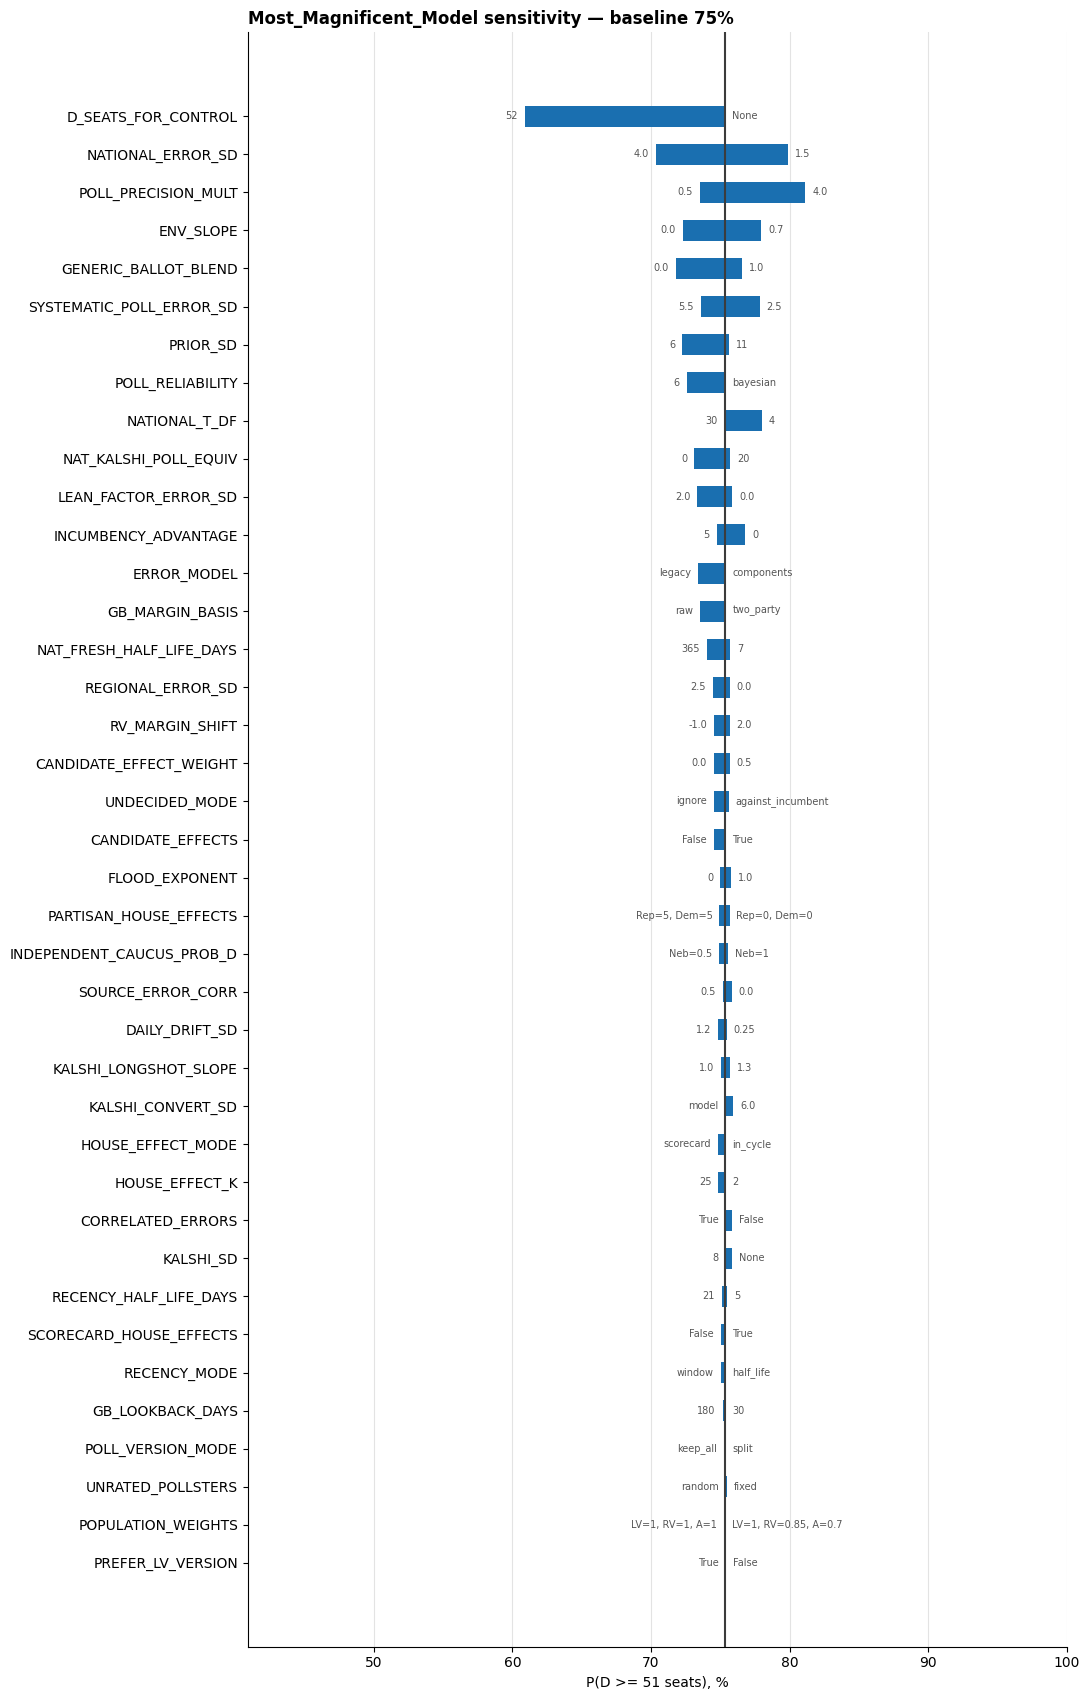

In [7]:
SWEEP_PARAMS = {
    # Model 1's sweep
    "RECENCY_HALF_LIFE_DAYS": [5, 7, 10, 14, 21],
    "ENV_SLOPE": [0.0, 0.2, 0.35, 0.5, 0.7],
    "GENERIC_BALLOT_BLEND": [0.0, 0.25, 0.5, 0.75, 1.0],
    "GB_MARGIN_BASIS": ["raw", "two_party"],
    "GB_LOOKBACK_DAYS": [30, 60, 90, 180],
    "PRIOR_SD": [6, 7.5, 9.35, 11, 14],
    "POLL_PRECISION_MULT": [0.5, 1.0, 2.0, 4.0],
    "SYSTEMATIC_POLL_ERROR_SD": [2.5, 3.0, 3.69, 4.5, 5.5],
    "PARTISAN_HOUSE_EFFECTS": [{"Republican": h, "Democrat": h} for h in (0, 1.5, 3, 5)],
    "RV_MARGIN_SHIFT": ["estimate", -1.0, -0.5, 0.0, 1.0, 2.0],
    "INCUMBENCY_ADVANTAGE": [0, 2, 3, 3.84, 5],
    "UNDECIDED_MODE": ["ignore", "proportional", "against_incumbent"],
    "POLL_VERSION_MODE": ["keep_all", "split", "prefer_h2h", "prefer_full_field"],
    "NATIONAL_ERROR_SD": [1.5, 2.0, 2.43, 3.0, 4.0],
    "REGIONAL_ERROR_SD": [0.0, 1.0, 1.6, 2.5],
    "NATIONAL_T_DF": [4, 8, 30],
    "LEAN_FACTOR_ERROR_SD": [0.0, 1.0, 2.0],
    "DAILY_DRIFT_SD": [0.25, 0.5, 0.84, 1.2],
    "ERROR_MODEL": ["components", "legacy"],
    "INDEPENDENT_CAUCUS_PROB_D": [{"Nebraska": p} for p in (0.5, 0.8, 1.0)],
    "D_SEATS_FOR_CONTROL": [None, 52],
    # From Pray_For_The_Floor
    "KALSHI_SD": [None, 5, 8, 12, 17],
    "POLL_RELIABILITY": ["bayesian", 1, 3, 6],
    "RECENCY_MODE": ["half_life", "window"],
    "POPULATION_WEIGHTS": [{"LV": 1.0, "RV": 0.85, "A": 0.7}, {"LV": 1.0, "RV": 0.9, "A": 0.8}, {"LV": 1.0, "RV": 1.0, "A": 1.0}],
    "UNRATED_POLLSTERS": ["fixed", "random"],
    "SCORECARD_HOUSE_EFFECTS": [False, True],
    "NAT_KALSHI_POLL_EQUIV": [0, 2, 5, 10, 20],
    "FLOOD_EXPONENT": [0, 0.5, 1.0],
    "CORRELATED_ERRORS": [False, True],
    "SOURCE_ERROR_CORR": [0.0, 0.15, 0.3, 0.5],
    # New in Most_Magnificent_Model
    "CANDIDATE_EFFECTS": [False, True],
    "CANDIDATE_EFFECT_WEIGHT": [0.0, 0.15, 0.295, 0.5],
    "KALSHI_LONGSHOT_SLOPE": [1.0, 1.15, 1.3],
    "KALSHI_CONVERT_SD": ["model", 4.69, 6.0],
    "PREFER_LV_VERSION": [False, True],
    "HOUSE_EFFECT_MODE": ["scorecard", "in_cycle"],
    "HOUSE_EFFECT_K": [2, 5, 10, 25],
    "NAT_FRESH_HALF_LIFE_DAYS": [7, 14, 30, 365],
}
SWEEP_TRACK_STATES = ["Maine", "North Carolina", "Ohio", "Texas", "Iowa", "Alaska", "Michigan", "Nebraska"]


def value_label(v):
    if v is None:
        return "None"
    if isinstance(v, dict):
        return ", ".join(f"{k.split('/')[0][:3]}={x:g}" for k, x in v.items())
    return str(v)


base = run_model(DATA, CONFIG, n_sims=SIM_N, verbose=False)["summary"]
rows = []
for key, values in SWEEP_PARAMS.items():
    for v in values:
        res = run_model(DATA, {**copy.deepcopy(CONFIG), key: v}, n_sims=SIM_N, verbose=False)
        rows.append({"param": key, "value": value_label(v), "is_default": (v == CONFIG[key]) if not isinstance(v, float) else np.isclose(v, CONFIG[key]) if isinstance(CONFIG[key], (int, float)) else False, "p_d_51": res["summary"]["p_d_51"],
                     "exp_d_seats": res["summary"]["exp_d_seats"],
                     **{f"P(D) {st}": res["races"].loc[st, "p_dem"] for st in SWEEP_TRACK_STATES}})
sweep = pd.DataFrame(rows)
sweep.to_csv(TEST_DIR / "sensitivity_sweep.csv", index=False)

rng_ = sweep.groupby("param")["p_d_51"].agg(["min", "max"])
lo = sweep.loc[sweep.groupby("param")["p_d_51"].idxmin()].set_index("param")["value"]
hi = sweep.loc[sweep.groupby("param")["p_d_51"].idxmax()].set_index("param")["value"]
rng_ = rng_.assign(span=rng_["max"] - rng_["min"]).sort_values("span")
fig, ax = plt.subplots(figsize=(11, 0.4 * len(rng_) + 1.5))
y = np.arange(len(rng_))
ax.barh(y, 100 * rng_["span"], left=100 * rng_["min"], height=0.55, color="#1A6FB0", zorder=3)
ax.axvline(100 * base["p_d_51"], color="#3C3C3C", lw=1.5, zorder=4)
for i, (prm, rr) in enumerate(rng_.iterrows()):
    ax.text(100 * rr["min"] - 0.5, i, lo[prm], ha="right", va="center", fontsize=7, color="#555555")
    ax.text(100 * rr["max"] + 0.5, i, hi[prm], ha="left", va="center", fontsize=7, color="#555555")
ax.set_yticks(y, rng_.index)
ax.set_xlabel("P(D >= 51 seats), %")
ax.grid(axis="x", color="#E3E3E3", zorder=0)
ax.spines[["right", "top"]].set_visible(False)
ax.set_title(f"Most_Magnificent_Model sensitivity — baseline {base['p_d_51']:.0%}", loc="left", fontweight="bold")
ax.set_xlim(max(0, 100 * rng_["min"].min() - 20), min(100, 100 * rng_["max"].max() + 20))
fig.tight_layout()
fig.savefig(TEST_DIR / "sensitivity_tornado.png", dpi=200, bbox_inches="tight")
plt.show()
top = rng_.sort_values("span", ascending=False).head(3)
check("E", "most influential settings", "PASS", "; ".join(f"{k}: {v['min']:.0%}-{v['max']:.0%}" for k, v in top.iterrows()))

### E2. Which races are most assumption-sensitive?
For each setting, the spread (max − min) of each tracked state's P(D win) across the values tried (Model 1's table). Large numbers flag races where the team's choices matter most.

In [8]:
state_cols = [c for c in sweep.columns if c.startswith("P(D) ")]
spread = sweep.groupby("param")[state_cols].agg(lambda x: x.max() - x.min())
spread.columns = [c.replace("P(D) ", "") for c in state_cols]
spread.to_csv(TEST_DIR / "state_sensitivity.csv")
try:
    display(spread.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None))
except (AttributeError, ImportError):
    display(spread.round(2))

,Maine,North Carolina,Ohio,Texas,Iowa,Alaska,Michigan,Nebraska
param,,,,,,,,
CANDIDATE_EFFECTS,5%,0%,2%,0%,0%,4%,1%,2%
CANDIDATE_EFFECT_WEIGHT,8%,0%,4%,0%,0%,7%,1%,4%
CORRELATED_ERRORS,4%,0%,4%,3%,1%,2%,3%,3%
DAILY_DRIFT_SD,3%,1%,2%,2%,0%,1%,3%,2%
D_SEATS_FOR_CONTROL,0%,0%,0%,0%,0%,0%,0%,0%
ENV_SLOPE,3%,0%,3%,4%,5%,5%,2%,3%
ERROR_MODEL,1%,0%,3%,0%,0%,2%,1%,1%
FLOOD_EXPONENT,2%,0%,0%,2%,2%,3%,1%,0%
GB_LOOKBACK_DAYS,0%,0%,0%,0%,0%,0%,0%,0%


### E3. The two on/off toggles
`SCORECARD_HOUSE_EFFECTS` changes each poll's *margin*; `CORRELATED_ERRORS` changes each race's *uncertainty*. They're independent, so all four combinations are valid.

In [9]:
rows = []
for he in (False, True):
    for ce in (False, True):
        res = run_model(DATA, {**CONFIG, "SCORECARD_HOUSE_EFFECTS": he, "CORRELATED_ERRORS": ce}, n_sims=SIM_N, verbose=False)
        comp = res["races"]
        rows.append({"SCORECARD_HOUSE_EFFECTS": he, "CORRELATED_ERRORS": ce, "P(D >= 51)": res["summary"]["p_d_51"],
                     "D seats": res["summary"]["exp_d_seats"], "avg race sd": comp["post_sd"].mean(),
                     "P(D) Maine": comp.loc["Maine", "p_dem"], "P(D) Texas": comp.loc["Texas", "p_dem"]})
toggles = pd.DataFrame(rows)
toggles.to_csv(TEST_DIR / "toggles.csv", index=False)
show_df(toggles, {"P(D >= 51)": "{:.1%}", "D seats": "{:.1f}", "avg race sd": "{:.2f}", "P(D) Maine": "{:.0%}", "P(D) Texas": "{:.0%}"})
spread_t = toggles["P(D >= 51)"].max() - toggles["P(D >= 51)"].min()
check("E", "toggle combinations agree", "PASS" if spread_t < 0.05 else "WARN", f"P(51+) spread {spread_t:.1%} across the 4 combinations")

,SCORECARD_HOUSE_EFFECTS,CORRELATED_ERRORS,P(D >= 51),D seats,avg race sd,P(D) Maine,P(D) Texas
0,False,False,75.6%,52.2,5.77,79%,72%
1,False,True,75.0%,52.2,6.32,75%,69%
2,True,False,75.8%,52.2,5.77,78%,72%
3,True,True,75.4%,52.2,6.32,74%,70%


### E4. Random grades: how much do they matter?
Compares `UNRATED_POLLSTERS = "random"` (redrawn in every simulation) with Model 1's `"fixed"` lowest grade, at the full number of simulations.

In [10]:
res_fixed = run_model(DATA, {**CONFIG, "UNRATED_POLLSTERS": "fixed"}, verbose=False)
cmp = pd.DataFrame({"random (this run)": r["p_dem"], "fixed (Model 1)": res_fixed["races"]["p_dem"]})
cmp["difference"] = cmp["random (this run)"] - cmp["fixed (Model 1)"]
cmp = cmp[cmp["difference"].abs() > 0.005].sort_values("difference")
print(f"P(D >= 51): random {RES['summary']['p_d_51']:.1%} vs fixed {res_fixed['summary']['p_d_51']:.1%}")
show_df(cmp, {c: "{:.1%}" for c in cmp.columns}) if len(cmp) else print("No race moves by more than half a point.")
check("E", "random vs fixed grades", "PASS", f"P(51+) {RES['summary']['p_d_51']:.1%} vs {res_fixed['summary']['p_d_51']:.1%}; "
      f"{len(cmp)} races move by more than 0.5 pts")

P(D >= 51): random 75.8% vs fixed 75.1%


,random (this run),fixed (Model 1),difference
State,,,
Alaska,59.5%,62.8%,-3.4%
New Hampshire,95.0%,94.5%,0.5%
Florida,10.1%,9.5%,0.6%
Montana,3.8%,3.1%,0.7%
Iowa,45.4%,44.6%,0.8%
Kansas,47.7%,46.6%,1.1%
Ohio,76.3%,75.1%,1.2%
South Carolina,28.4%,26.7%,1.7%
Michigan,87.7%,85.6%,2.1%


### E4b. What each change did
Turns each change back to Pray_For_The_Floor's behaviour **one at a time** (everything else as in this run), at the full number of simulations. "Everything back to Pray" is Pray's method on today's data, so differences from Pray's own output come from method, not data.

In [11]:
PRAY_LIKE = {"CANDIDATE_EFFECTS": False, "ERROR_MODEL": "legacy", "KALSHI_SD": 17.0, "KALSHI_CONVERT_SD": "model",
             "KALSHI_LONGSHOT_SLOPE": 1.0, "KALSHI_USE_RANGE": (0.0, 1.0), "GENERIC_BALLOT_BLEND": 0.5, "NAT_FRESH_HALF_LIFE_DAYS": 1e9,
             "RV_MARGIN_SHIFT": -0.5, "PREFER_LV_VERSION": False, "HOUSE_EFFECT_MODE": "scorecard", "RECENCY_HALF_LIFE_DAYS": 21, "PRIOR_SD": 7.5, "SYSTEMATIC_POLL_ERROR_SD": 4.5, "DAILY_DRIFT_SD": 0.25,
             "INCUMBENCY_ADVANTAGE": 2.0, "T_DF": 5, "CORR_NATIONAL": 0.45, "CORR_REGION": 0.15}
groups = {
    "calibration (prior SD, poll floor, drift, incumbency, tails)": ["PRIOR_SD", "SYSTEMATIC_POLL_ERROR_SD", "DAILY_DRIFT_SD", "INCUMBENCY_ADVANTAGE", "T_DF", "CORR_NATIONAL", "CORR_REGION"],
    "candidate effects": ["CANDIDATE_EFFECTS"],
    "error components": ["ERROR_MODEL"],
    "Kalshi (weight, conversion, longshot, range)": ["KALSHI_SD", "KALSHI_CONVERT_SD", "KALSHI_LONGSHOT_SLOPE", "KALSHI_USE_RANGE"],
    "national signals (GB blend, fresh polls)": ["GENERIC_BALLOT_BLEND", "NAT_FRESH_HALF_LIFE_DAYS"],
    "RV shift + LV preference": ["RV_MARGIN_SHIFT", "PREFER_LV_VERSION"],
    "in-cycle house effects": ["HOUSE_EFFECT_MODE"],
    "7-day half-life": ["RECENCY_HALF_LIFE_DAYS"],
}
rows = [{"change undone": "none (this run)", "P(D >= 51)": RES["summary"]["p_d_51"], "D seats": RES["summary"]["exp_d_seats"],
         **{f"P(D) {st}": r.loc[st, "p_dem"] for st in ["Maine", "Alaska", "Nebraska", "Kansas", "Texas", "Ohio"]}}]
for name, keys in list(groups.items()) + [("EVERYTHING back to Pray", list(PRAY_LIKE))]:
    res = run_model(DATA, {**CONFIG, **{k: PRAY_LIKE[k] for k in keys}}, verbose=False)
    rows.append({"change undone": name, "P(D >= 51)": res["summary"]["p_d_51"], "D seats": res["summary"]["exp_d_seats"],
                 **{f"P(D) {st}": res["races"].loc[st, "p_dem"] for st in ["Maine", "Alaska", "Nebraska", "Kansas", "Texas", "Ohio"]}})
attrib = pd.DataFrame(rows).set_index("change undone")
attrib.to_csv(TEST_DIR / "change_attribution.csv")
show_df(attrib, {c: "{:.1%}" for c in attrib.columns if c != "D seats"} | {"D seats": "{:.2f}"})

,P(D >= 51),D seats,P(D) Maine,P(D) Alaska,P(D) Nebraska,P(D) Kansas,P(D) Texas,P(D) Ohio
change undone,,,,,,,,
none (this run),75.8%,52.21,75.1%,59.5%,25.3%,47.7%,69.5%,76.3%
"calibration (prior SD, poll floor, drift, incumbency, tails)",75.6%,52.11,81.9%,59.3%,23.3%,42.3%,65.0%,74.6%
candidate effects,75.0%,52.13,79.7%,55.4%,23.1%,45.7%,69.5%,73.7%
error components,73.2%,52.25,76.1%,59.9%,25.0%,47.6%,70.7%,77.3%
"Kalshi (weight, conversion, longshot, range)",76.1%,52.28,75.8%,56.5%,26.0%,47.7%,68.4%,75.9%
"national signals (GB blend, fresh polls)",73.5%,52.02,73.7%,57.7%,24.4%,45.8%,68.0%,75.0%
RV shift + LV preference,75.7%,52.20,75.3%,57.4%,25.3%,47.6%,68.9%,76.4%
in-cycle house effects,75.1%,52.14,76.7%,55.0%,24.9%,50.2%,70.0%,76.2%
7-day half-life,75.9%,52.21,75.6%,61.5%,25.3%,46.7%,68.0%,78.2%


### E5. Simulation noise and random seeds
Re-runs the full model with 5 different random seeds. If P(51+) jumps by more than a point or two, raise `N_SIMS`.

In [12]:
seed_rows = []
for sd in [CONFIG["SEED"], 1, 7, 42, 99]:
    res = run_model(DATA, {**CONFIG, "SEED": sd}, verbose=False)["summary"]
    seed_rows.append({"seed": sd, "P(D >= 51)": res["p_d_51"], "D seats": res["exp_d_seats"]})
seeds = pd.DataFrame(seed_rows)
show_df(seeds, {"P(D >= 51)": "{:.1%}", "D seats": "{:.2f}"})
rg = seeds["P(D >= 51)"].max() - seeds["P(D >= 51)"].min()
check("E", "stable across random seeds", "PASS" if rg < 0.02 else "WARN", f"P(51+) range {rg:.1%} over 5 seeds at {CONFIG['N_SIMS']:,} simulations")
show("E")

,seed,P(D >= 51),D seats
0,2026,75.8%,52.21
1,1,76.3%,52.24
2,7,76.0%,52.24
3,42,76.1%,52.23
4,99,76.3%,52.23


,check,status,detail
0,most influential settings,PASS,D_SEATS_FOR_CONTROL: 61%-75%; NATIONAL_ERROR_SD: 70%-80%; POLL_PRECISION_MULT: 74%-81%
1,toggle combinations agree,PASS,P(51+) spread 0.8% across the 4 combinations
2,random vs fixed grades,PASS,P(51+) 75.8% vs 75.1%; 9 races move by more than 0.5 pts
3,stable across random seeds,PASS,"P(51+) range 0.5% over 5 seeds at 100,000 simulations"


## F. Trajectory: the forecast week by week
Re-runs the model **as of** each Monday since September 7 (backtests). Each run uses only polls *released* by that date and **that day's Kalshi race prices**; the national numbers use polls only. The dashed line is Kalshi's own P(Democrats win the Senate) on the same dates.

*Note:* the first time this runs, it downloads Kalshi's daily price history (one request per market, ~30 seconds) and saves it to `Data_Cache/`.

kalshi_history_cache.csv: fetched 4795 rows live


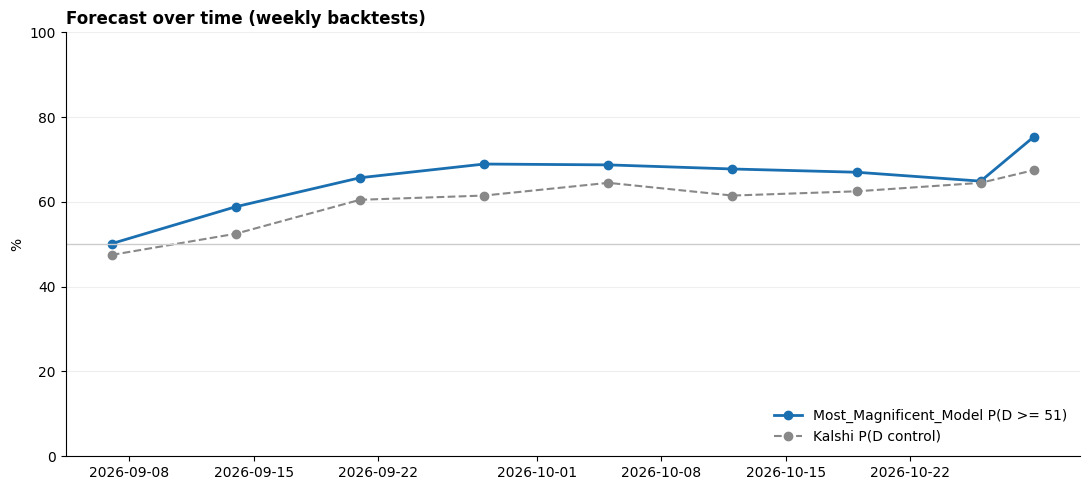

,P(D >= 51),D seats,Kalshi P(control),polls used
date,,,,
2026-09-07 00:00:00,50.2%,50.5,47.5%,188
2026-09-14 00:00:00,58.9%,51.0,52.5%,201
2026-09-21 00:00:00,65.7%,51.4,60.5%,217
2026-09-28 00:00:00,68.9%,51.6,61.5%,236
2026-10-05 00:00:00,68.7%,51.6,64.5%,256
2026-10-12 00:00:00,67.8%,51.6,61.5%,277
2026-10-19 00:00:00,67.0%,51.5,62.5%,296
2026-10-26 00:00:00,64.9%,51.5,64.5%,336
2026-10-29 00:00:00,75.4%,52.2,67.5%,366


,check,status,detail
0,week-to-week stability,PASS,largest weekly move 10%


In [13]:
dates = list(pd.date_range("2026-09-07", today - pd.Timedelta(days=1), freq="W-MON")) + [today]
traj = []
for d in dates:
    try:
        res = run_model(DATA, {**CONFIG, "AS_OF_DATE": None if d == today else d.strftime("%Y-%m-%d")}, n_sims=SIM_N, verbose=False)
    except Exception as e:  # e.g. no Kalshi history available offline
        print(f"{d:%Y-%m-%d}: skipped ({type(e).__name__}: {e})")
        continue
    kt_ = res["kalshi"]
    traj.append({"date": d, "P(D >= 51)": res["summary"]["p_d_51"], "D seats": res["summary"]["exp_d_seats"],
                 "Kalshi P(control)": float(kt_.loc["CONTROL", "p_opp"]) if "CONTROL" in kt_.index else np.nan,
                 "polls used": len(res["polls"])})
traj = pd.DataFrame(traj).set_index("date")
traj.to_csv(TEST_DIR / "trajectory.csv")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(traj.index, 100 * traj["P(D >= 51)"], marker="o", color="#1A6FB0", lw=2, label="Most_Magnificent_Model P(D >= 51)")
ax.plot(traj.index, 100 * traj["Kalshi P(control)"], marker="o", color="#888888", lw=1.5, ls="--", label="Kalshi P(D control)")
ax.axhline(50, color="#CCCCCC", lw=1)
ax.set_ylim(0, 100)
ax.set_ylabel("%")
ax.grid(axis="y", color="#EEEEEE")
ax.spines[["right", "top"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Forecast over time (weekly backtests)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(TEST_DIR / "trajectory.png", dpi=200, bbox_inches="tight")
plt.show()
show_df(traj, {"P(D >= 51)": "{:.1%}", "D seats": "{:.1f}", "Kalshi P(control)": "{:.1%}"})
jump = traj["P(D >= 51)"].diff().abs().max() if len(traj) > 1 else 0.0
check("F", "week-to-week stability", "PASS" if jump < 0.15 else "WARN", f"largest weekly move {jump:.0%}")
show("F")

## G. Summary of every check
Saved to `Output/testing/checks.csv` (also read by `run_all.py`). Before publishing a run, make sure there are no FAILs and that you understand every WARN.

In [14]:
summary = pd.DataFrame(CHECKS)
summary.to_csv(TEST_DIR / "checks.csv", index=False)
counts = summary["status"].value_counts()
print(f"{counts.get('PASS', 0)} PASS | {counts.get('WARN', 0)} WARN | {counts.get('FAIL', 0)} FAIL")
try:
    display(summary.style.map(lambda v: COLORS.get(v, ""), subset=["status"]))
except (AttributeError, ImportError):
    display(summary)

35 PASS | 6 WARN | 0 FAIL


,section,check,status,detail
0,A,source: votehub_senate_cache.csv,PASS,live
1,A,source: votehub_generic_ballot_cache.csv,PASS,live
2,A,source: votehub_approval_cache.csv,PASS,live
3,A,source: kalshi_races_cache.csv,PASS,live
4,A,source: kalshi_national_cache.csv,PASS,live
5,A,newest state poll,PASS,2026-10-28 (1 days old)
6,A,newest generic ballot poll (VoteHub),WARN,2026-10-04 (25 days old) - Kalshi averages fill the gap
7,A,newest approval poll (VoteHub),WARN,2026-10-06 (23 days old) - Kalshi averages fill the gap
8,A,Kalshi race prices date,PASS,fetched 2026-10-29
9,A,Kalshi races found,PASS,35/35
